# Predicting Diabetes Progression with Linear Regression
**Simple Machine Learning Task**

## Description
A doctor has 10 measurements of a patient (age, BMI, blood pressure, blood tests).
The doctor wants to **guess one number**: how much will the diabetes get worse after 1 year?

We will train the computer to make this guess. We use the simplest algorithm for guessing numbers using: **Linear Regression**.

**Linear Regression in one example:**
A taxi costs Rs. 50 to start and Rs. 30 for every km. So `price = 50 + 30 x km`.
If you know the km, you can guess the price. Linear Regression finds a formula like this by itself, from data.

## What we will do (7 easy steps)
1. Import tools
2. Load the data
3. Look at the data
4. Split the data (study part and exam part)
5. Train the model
6. Check the predictions
7. Measure the quality (metrics)

## Step 1: Import tools
A **library** is a ready-made toolbox written by other people. We import it, so we do not have to write everything ourselves.

### The libraries (what each one does)
| Library | Definition (one line) |
|---|---|
| **pandas** | Makes tables of data (called DataFrames), like Excel inside Python |
| **numpy** | Does fast maths on numbers (average, square root, etc.) |
| **matplotlib** | Draws charts (histogram, scatter plot, bar chart) |
| **scikit-learn** | Gives us the dataset, the ML model and the metrics |

### What each line of the code does
| Code line | Meaning |
|---|---|
| `import pandas as pd` | Loads pandas. `pd` is its short name |
| `import numpy as np` | Loads numpy. `np` is its short name |
| `import matplotlib.pyplot as plt` | Loads the chart tool. `plt` is its short name |
| `load_diabetes` | Function that loads the Diabetes dataset (442 patients) |
| `train_test_split` | Function that splits the data into a training part and a test part |
| `LinearRegression` | The ML model (algorithm) that guesses numbers |
| `mean_absolute_error` | Metric **MAE**: the average size of the error |
| `mean_squared_error` | Metric **MSE**: the average of the squared errors |
| `r2_score` | Metric **R2**: how much of the pattern the model explains |
| `pd.set_option(...)` | Setting to show normal numbers (like 0.0001) instead of 1e-04 |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.float_format", lambda x: f"{x:.4f}")   # show normal numbers, no 1e-05 style
print("Tools are ready")

Tools are ready


## Step 2: Load the data
- `X` = the **inputs** (the 10 measurements). These are called **features**.
- `y` = the **answer** we want to guess. This is called the **target**.

`df.head()` shows the first 5 rows of the table of dataset.

| Column | Meaning |
|---|---|
| age | Age |
| sex | Sex |
| bmi | Body weight index |
| bp | Blood pressure |
| s1 to s6 | Six blood test results |

In [2]:
data = load_diabetes(as_frame=True)
df = data.frame            # full table
X = data.data              # inputs
y = data.target            # answer to predict

print("Rows and columns:", df.shape)
print("Missing values  :", df.isnull().sum().sum())
df.head()

Rows and columns: (442, 11)
Missing values  : 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.0381,0.0507,0.0617,0.0219,-0.0442,-0.0348,-0.0434,-0.0026,0.0199,-0.0176,151.0000
1,-0.0019,-0.0446,-0.0515,-0.0263,-0.0084,-0.0192,0.0744,-0.0395,-0.0683,-0.0922,75.0000
2,0.0853,0.0507,0.0445,-0.0057,-0.0456,-0.0342,-0.0324,-0.0026,0.0029,-0.0259,141.0000
3,-0.0891,-0.0446,-0.0116,-0.0367,0.0122,0.0250,-0.0360,0.0343,0.0227,-0.0094,206.0000
4,0.0054,-0.0446,-0.0364,0.0219,0.0039,0.0156,0.0081,-0.0026,-0.0320,-0.0466,135.0000


## Step 3: Description of the data
Always look at the data first, like tasting food before serving.

### 3.1 Basic numbers
`describe()` shows the average (mean), smallest (min) and biggest (max) value of every column.

In [3]:
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000
mean,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,152.1335
std,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,77.0930
min,-0.1072,-0.0446,-0.0903,-0.1124,-0.1268,-0.1156,-0.1023,-0.0764,-0.1261,-0.1378,25.0000
25%,-0.0373,-0.0446,-0.0342,-0.0367,-0.0342,-0.0304,-0.0351,-0.0395,-0.0332,-0.0332,87.0000
50%,0.0054,-0.0446,-0.0073,-0.0057,-0.0043,-0.0038,-0.0066,-0.0026,-0.0019,-0.0011,140.5000
75%,0.0381,0.0507,0.0312,0.0356,0.0284,0.0298,0.0293,0.0343,0.0324,0.0279,211.5000
max,0.1107,0.0507,0.1706,0.1320,0.1539,0.1988,0.1812,0.1852,0.1336,0.1356,346.0000


### 3.2 Target chart
This chart shows how many patients have each progression score.
The red line is the average.

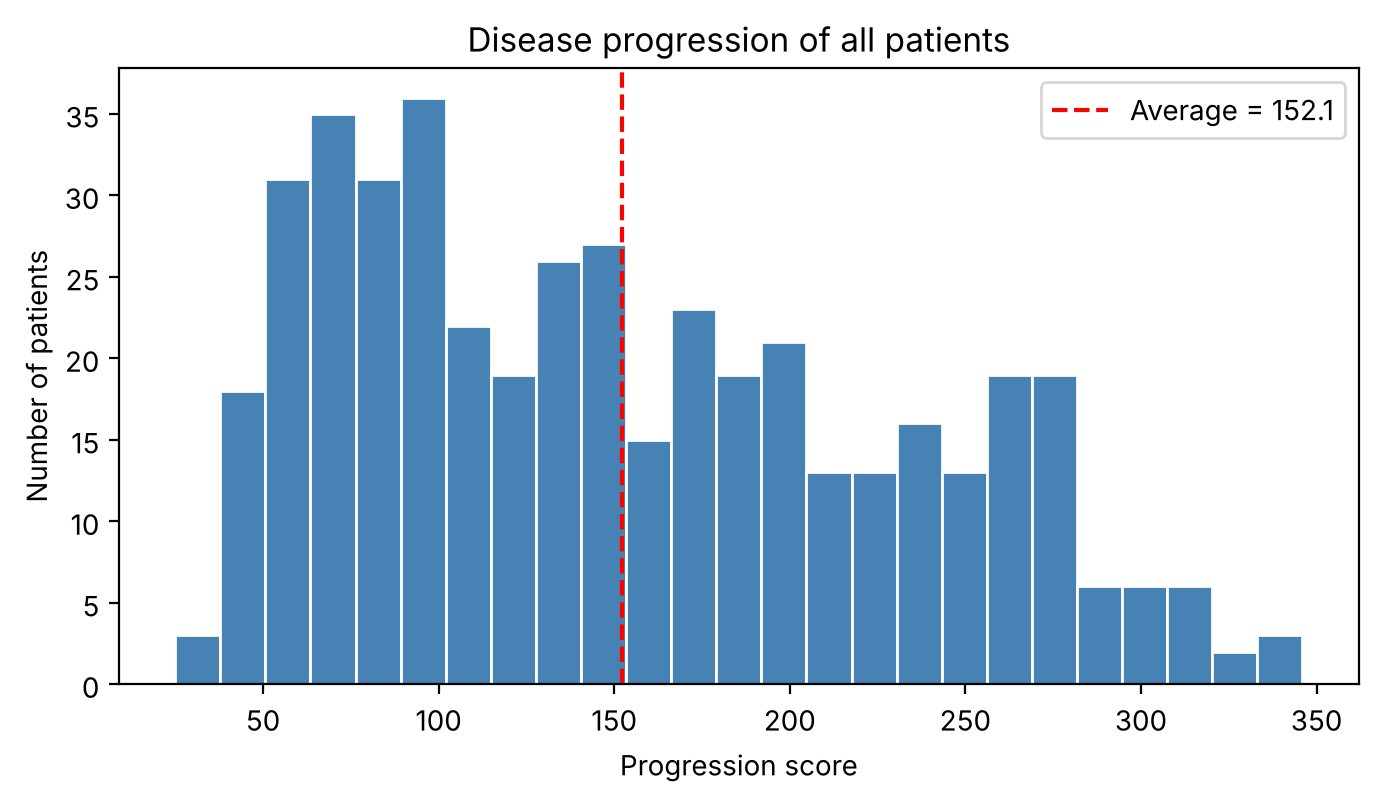

In [4]:
plt.figure(figsize=(8, 4))
plt.hist(y, bins=25, color="steelblue", edgecolor="white")
plt.axvline(y.mean(), color="red", linestyle="--", label=f"Average = {y.mean():.1f}")
plt.title("Disease progression of all patients")
plt.xlabel("Progression score")
plt.ylabel("Number of patients")
plt.legend()
plt.show()

### 3.3 Which input is related to the answer?
**Correlation** is a number from -1 to +1:
- close to **+1**: when the input goes up, the answer goes up
- close to **-1**: when the input goes up, the answer goes down
- close to **0**: no relation

Look for the biggest bars. These inputs are the most related to the answer.

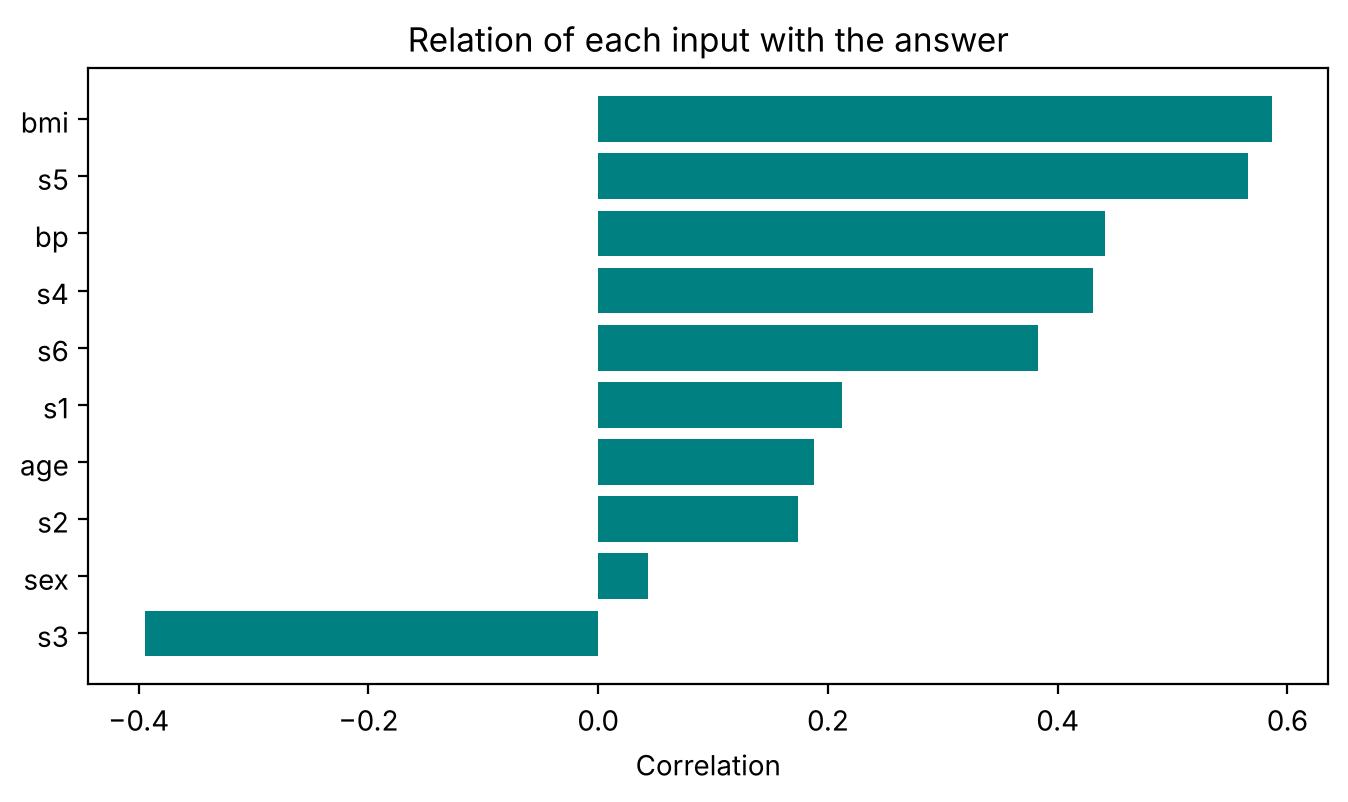

In [5]:
corr = X.corrwith(y).sort_values()

plt.figure(figsize=(8, 4))
plt.barh(corr.index, corr.values, color="teal")
plt.title("Relation of each input with the answer")
plt.xlabel("Correlation")
plt.show()

### 3.4 One input against the answer
Every dot is one patient. The red line shows the direction: higher BMI usually means higher progression.

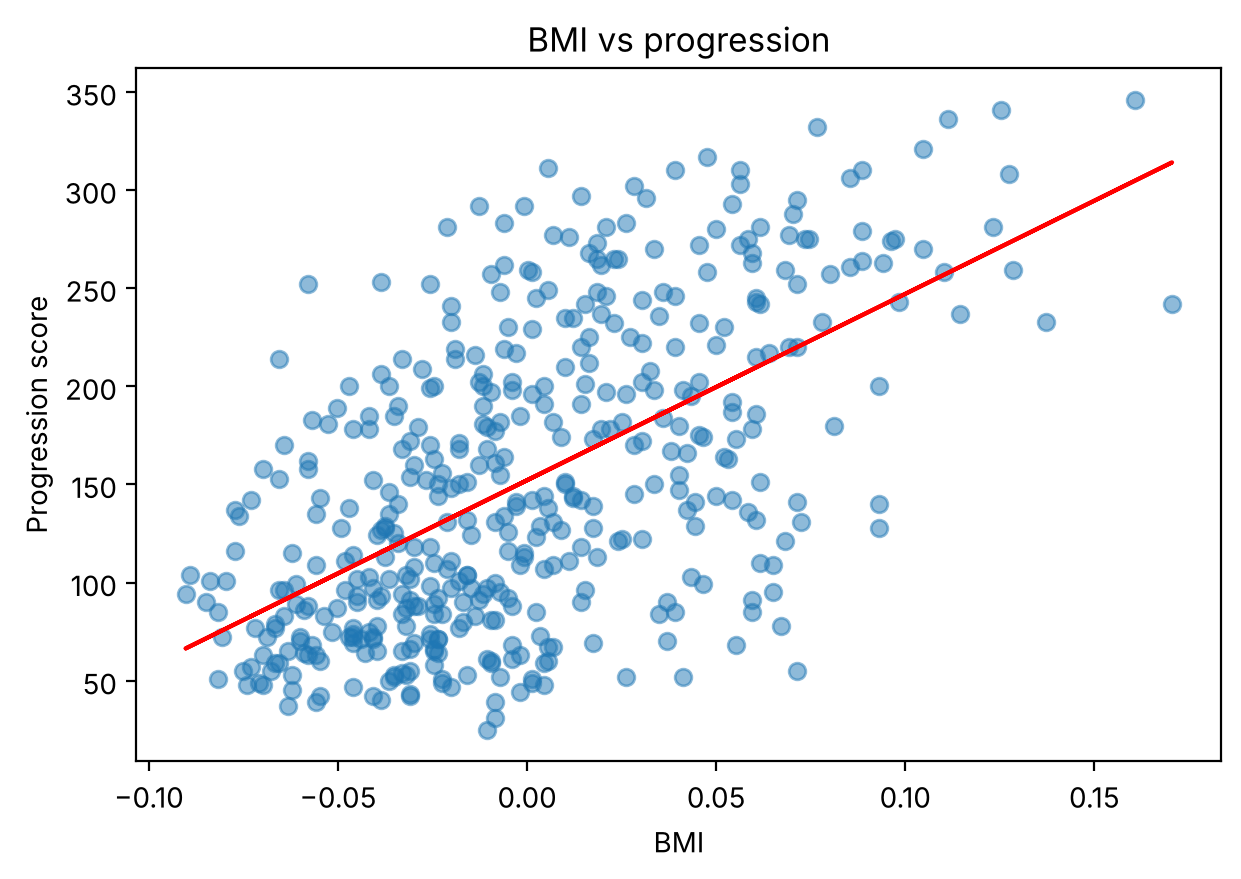

In [6]:
plt.figure(figsize=(7, 4.5))
plt.scatter(X["bmi"], y, alpha=0.5)
slope, start = np.polyfit(X["bmi"], y, 1)
plt.plot(X["bmi"], slope * X["bmi"] + start, color="red")
plt.title("BMI vs progression")
plt.xlabel("BMI")
plt.ylabel("Progression score")
plt.show()

## Step 4: Split the data
A student must not be tested with the same questions he studied.
So we split the patients:
- **Training data (80%)**: the model studies these.
- **Test data (20%)**: hidden. We use it only to check the model, like an exam.

`random_state=42` means we get the same split every time we run the notebook.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Patients for training:", len(X_train))
print("Patients for testing :", len(X_test))

Patients for training: 353
Patients for testing : 89


## Step 5: Train the model
Only two lines:
1. Create the model.
2. `fit` = **learn** from the training data.

After learning, the model has a number (weight) for each input. We print them, so you can see the formula it found:

`progression = start value + (w1 x age) + (w2 x sex) + ... + (w10 x s6)`

A **bigger positive weight** pushes the prediction up. A **negative weight** pushes it down.

In [8]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Start value:", round(model.intercept_, 4))
print()
print("Weights:")
print(pd.Series(model.coef_, index=X.columns))

Start value: 151.3456

Weights:
age     37.9040
sex   -241.9644
bmi    542.4288
bp     347.7038
s1    -931.4888
s2     518.0623
s3     163.4200
s4     275.3179
s5     736.1989
s6      48.6707
dtype: float64


## Step 6: Make predictions and check them
Now the model guesses the answers for the **test patients** (patients it has never seen).
We put the real answer and the guess side by side.

`Error` = real answer minus guess. A small error is good.

In [9]:
y_pred = model.predict(X_test)

result = pd.DataFrame({"Real answer": y_test.values, "Model guess": y_pred})
result["Error"] = result["Real answer"] - result["Model guess"]
result.head(10)

,Real answer,Model guess,Error
0,219.0000,139.5476,79.4524
1,70.0000,179.5172,-109.5172
2,202.0000,134.0388,67.9612
3,230.0000,291.4170,-61.4170
4,111.0000,123.7897,-12.7897
5,84.0000,92.1723,-8.1723
6,242.0000,258.2324,-16.2324
7,272.0000,181.3373,90.6627
8,94.0000,90.2241,3.7759
9,96.0000,108.6338,-12.6338


### Real vs guess chart
Every dot is one test patient.
- The **red line** is a perfect guess (guess = real).
- The **closer the dots are to the red line, the better** the model.

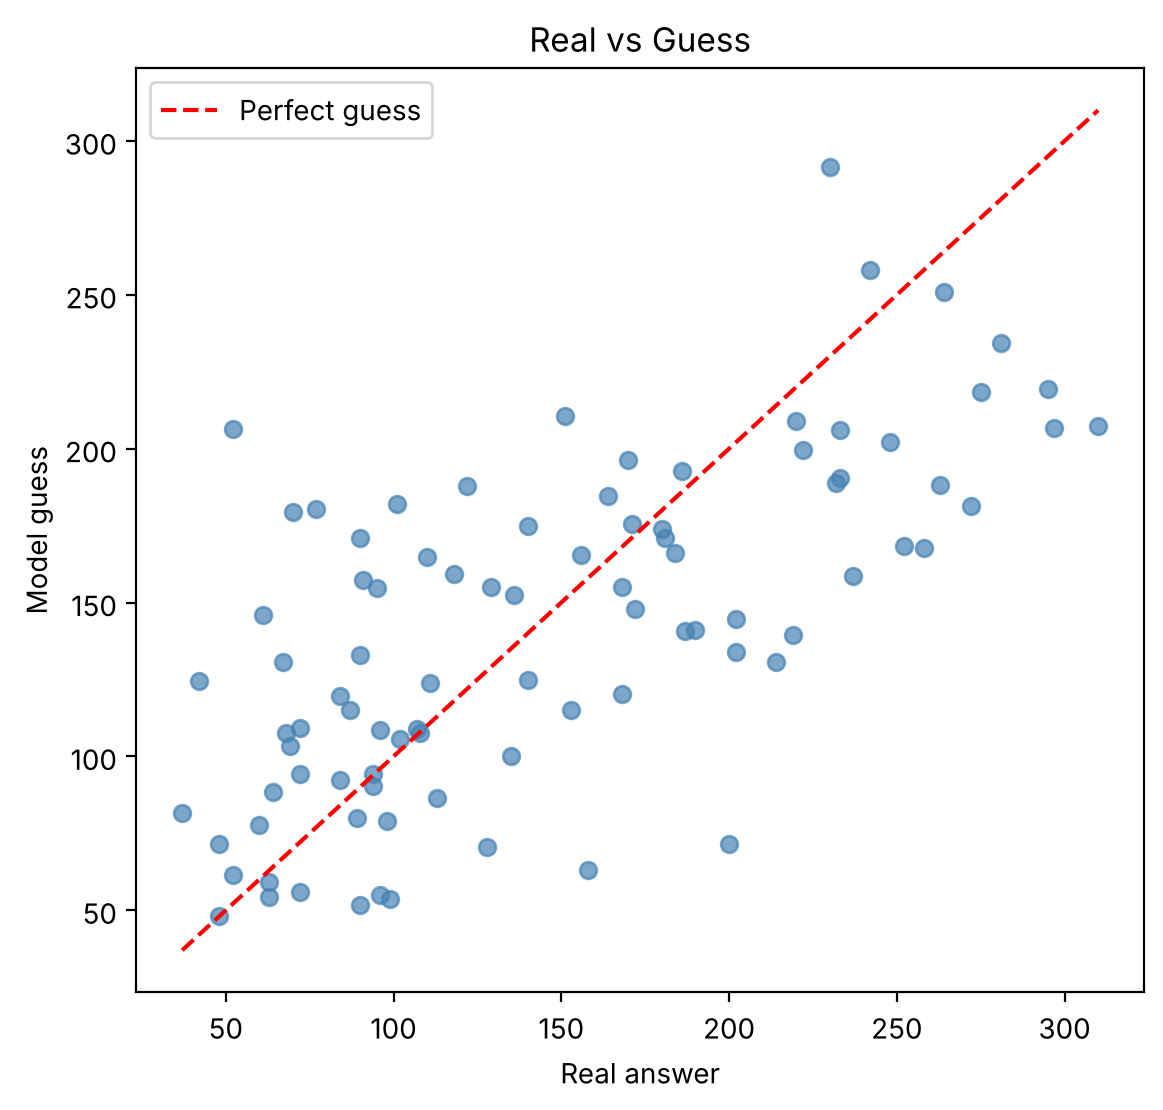

In [10]:
plt.figure(figsize=(6.5, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color="steelblue")
low, high = y_test.min(), y_test.max()
plt.plot([low, high], [low, high], color="red", linestyle="--", label="Perfect guess")
plt.xlabel("Real answer")
plt.ylabel("Model guess")
plt.title("Real vs Guess")
plt.legend()
plt.show()

## Step 7: Measure the quality (metrics)
A **metric** is a score that tells how good the model is.

**Small example:** 3 patients. Real = `100, 150, 200`. Guess = `110, 140, 230`.
The errors (without sign) are `10, 10, 30`.

| Metric | Meaning | Example | Good value |
|---|---|---|---|
| **MAE** | Average error | (10 + 10 + 30) / 3 = 16.67 | Small |
| **MSE** | Average of squared errors (big mistakes count a lot) | (100 + 100 + 900) / 3 = 366.67 | Small |
| **RMSE** | Square root of MSE. Same unit as the answer | sqrt(366.67) = 19.15 | Small |
| **R2** | How much of the ups and downs of the answer the model explains | - | Close to 1 |

**About R2:**
- R2 = 1 means perfect.
- R2 = 0 means no better than always guessing the average.
- R2 = 0.5 means the model explains about half of the pattern.

In [11]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  = {mae:.4f}")
print(f"MSE  = {mse:.4f}")
print(f"RMSE = {rmse:.4f}")
print(f"R2   = {r2:.4f}")

MAE  = 42.7941
MSE  = 2900.1936
RMSE = 53.8534
R2   = 0.4526


### Is the model better than a lazy guess?
The laziest guess is to say the **average** for every patient. Our model must beat that.

In [12]:
lazy_guess = np.full(len(y_test), y_train.mean())      # same average for everyone
lazy_rmse = np.sqrt(mean_squared_error(y_test, lazy_guess))

print(f"Lazy guess RMSE   : {lazy_rmse:.4f}")
print(f"Our model RMSE    : {rmse:.4f}")
print("Our model is better!" if rmse < lazy_rmse else "Our model is NOT better.")

Lazy guess RMSE   : 73.2225
Our model RMSE    : 53.8534
Our model is better!


### Which inputs matter most?
The bars are the weights from Step 5.
- **Green** = pushes the prediction up.
- **Red** = pushes the prediction down.
- **Longer bar** = more influence.

**Careful:** `s1` and `s2` are blood tests that move together (they are related to each other). So the model shares the work between them with opposite signs, and their individual bars should not be trusted too much. `bmi` and `s5` are easier to trust: both push the prediction up.

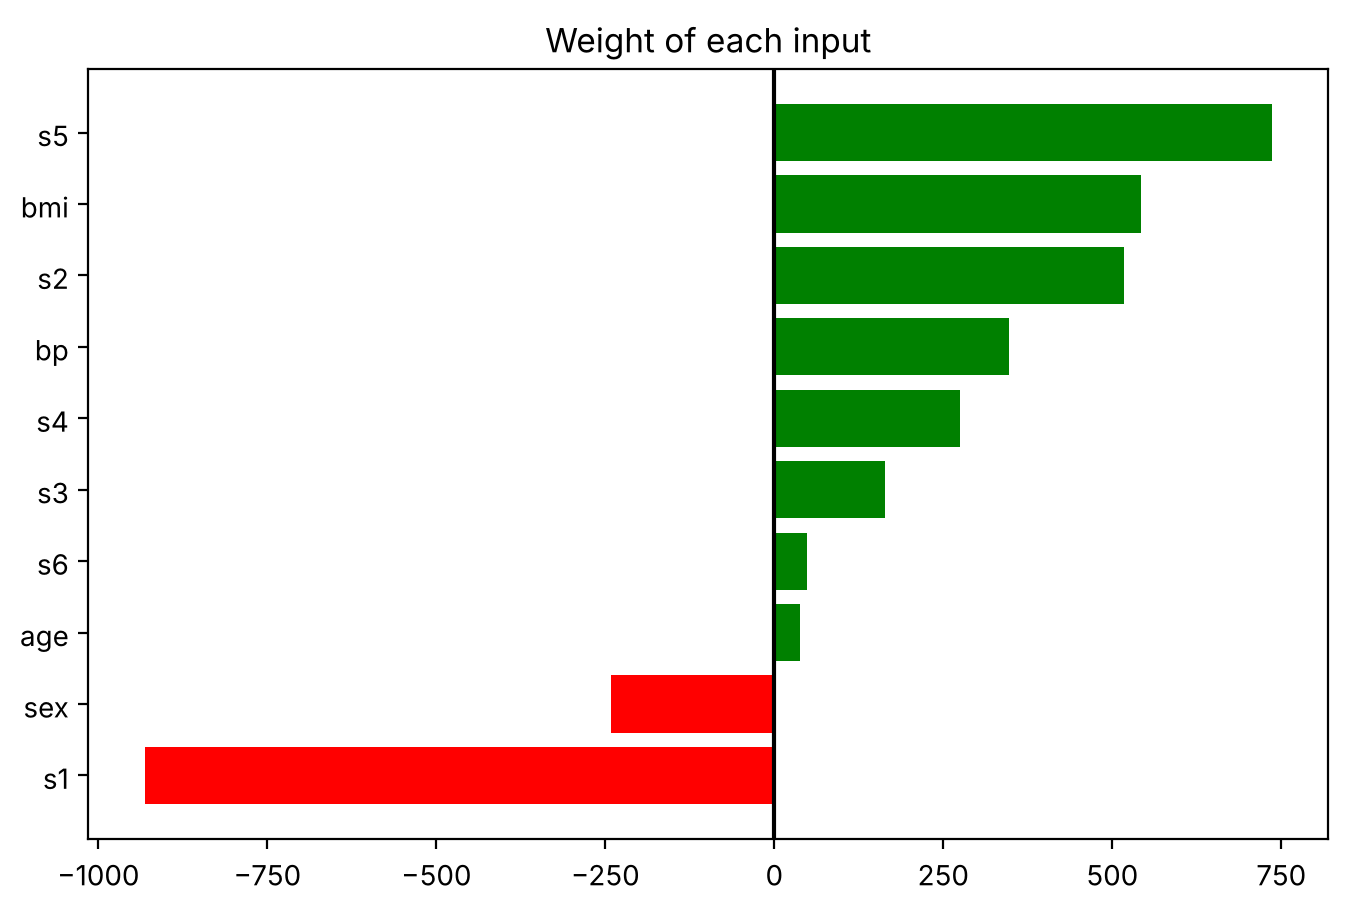

In [13]:
weights = pd.Series(model.coef_, index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(weights.index, weights.values, color=["red" if w < 0 else "green" for w in weights.values])
plt.axvline(0, color="black")
plt.title("Weight of each input")
plt.show()

## Conclusion (numbers are filled in automatically)

In [14]:
print(f"1. On average, the guess is wrong by about {mae:.1f} points (MAE).")
print(f"2. The model explains about {r2 * 100:.0f}% of the pattern (R2 = {r2:.2f}).")
print(f"3. The lazy guess has RMSE {lazy_rmse:.1f}, our model has {rmse:.1f}, so the model is better.")
print("4. BMI and s5 (a blood test) push the progression up. Read s1 and s2 carefully because they are related to each other.")

1. On average, the guess is wrong by about 42.8 points (MAE).
2. The model explains about 45% of the pattern (R2 = 0.45).
3. The lazy guess has RMSE 73.2, our model has 53.9, so the model is better.
4. BMI and s5 (a blood test) push the progression up. Read s1 and s2 carefully because they are related to each other.


### What we learned
- A **simple** model (Linear Regression) can learn from data and guess numbers for new patients.
- An R2 of about 0.45 is **normal for this dataset**. The data is small (442 patients) and has natural randomness. It is not a mistake.
- Steps we followed: **load, look, split, train, predict, measure**. Almost every Machine Learning project follows the same steps.

### Ideas for later (not needed now)
Try other algorithms, scale the data, or use cross-validation. These are next-level topics.